# RIKUY_DEEP: deteccion de defectos en piezas de fundicion

Flujo: ingesta y versionado del dataset (data-v1) -> CNN (cnn-v1) -> ResNet50 (resnet-v1) -> comparacion en test -> exportacion a TensorFlow.js.

Decisiones de diseno:

El dataset de Kaggle ya viene augmentado: no se aplica augmentation durante el entrenamiento.
data-v1 es el dataset tal como se descarga. El redimensionado ocurre en tf.data, no se duplica en disco.
Clase positiva (1) = defecto. El modelo devuelve P(defecto).
Validacion se usa para early stopping y umbral; test solo para el reporte final.

In [1]:
%pip install -q kagglehub dvc dvc-gdrive tensorflowjs

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pysal 25.7 requires packaging>=22, but you have packaging 20.9 which is incompatible.
google-adk 2.7.1 requires packaging>=21, but you have packaging 20.9 which is incompatible.
bigquery-magics 0.14.0 requires packaging>=24.2.0, but you have packaging 20.9 which is incompatible.
libpysal 4.14.1 requires packaging>=23.2, but you have packaging 20.9 which is incompatible.
pandas-gbq 0.30.0 requires packaging>=22.0.0, but you have packaging 20.9 which is incompatible.
db-dtypes 1.9.0 requires packaging>=24.2.0, but you have packaging 20.9 which is inco

## LIBRERIAS

In [2]:
import hashlib
import json
import os
import shutil
import shlex
import subprocess
import time
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from PIL import Image
from google.colab import drive
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,confusion_matrix, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import train_test_split
from tensorflow.keras import Model, layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator , load_img ,img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense, Conv2D, MaxPooling2D

## CONFIGURACIÓN KAGGLE Y GOOGLE DRIVE

In [3]:
drive.mount('/content/drive')

DATA_VERSION, CNN_VERSION, RESNET_VERSION = 'data-v1', 'cnn-v1', 'resnet-v1'
KAGGLE_DATASET = 'ravirajsinh45/real-life-industrial-dataset-of-casting-product'
IMAGE_EXTENSIONS = {'.jpeg', '.jpg', '.png'}

DRIVE_ROOT = Path('/content/drive/MyDrive')
PROJECT_DIR = DRIVE_ROOT / 'RIKUY_DEEP'
REPO_DIR = DRIVE_ROOT / 'ColabNotebooks' / 'RIKUY_DEEP_G2'
DATA_DIR = PROJECT_DIR / 'data'
RAW_DATA = DATA_DIR / 'casting_data'
REPO_DATA_DIR = REPO_DIR / 'data'
REMOTE_DIR = REPO_DIR / 'dvc_remote'
REGISTRY_DIR = PROJECT_DIR / 'model_registry'
EXPORT_DIR = PROJECT_DIR / 'exports'
SPLITS_CSV = PROJECT_DIR / 'splits.csv'

for directory in (PROJECT_DIR, DATA_DIR, RAW_DATA, REPO_DIR, REGISTRY_DIR, EXPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIR)
print(f'Proyecto y fuente de datos: {PROJECT_DIR}')
print(f'Datos crudos: {RAW_DATA}')
print(f'Repositorio: {REPO_DIR}')
print(f'Datos DVC: {REPO_DATA_DIR}')
print(f'Remoto DVC en Google Drive: {REMOTE_DIR}')
print(f'Registro de modelos: {REGISTRY_DIR}')
print(f'Modelos exportados: {EXPORT_DIR}')

Mounted at /content/drive
Proyecto y fuente de datos: /content/drive/MyDrive/RIKUY_DEEP
Datos crudos: /content/drive/MyDrive/RIKUY_DEEP/data/casting_data
Repositorio: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
Datos DVC: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data
Remoto DVC en Google Drive: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/dvc_remote
Registro de modelos: /content/drive/MyDrive/RIKUY_DEEP/model_registry
Modelos exportados: /content/drive/MyDrive/RIKUY_DEEP/exports


## Descargando el dataset

In [4]:
if not (RAW_DATA / 'def_front').exists() or not (RAW_DATA / 'ok_front').exists():
    print("Descargando dataset desde Kaggle con kagglehub...")
    path = Path(kagglehub.dataset_download(KAGGLE_DATASET))

    # Localizar la carpeta que contiene directamente las clases
    candidates = [
        path / 'casting_512x512' / 'casting_512x512',
        path / 'casting_512x512',
        path
    ]
    source_dir = next((c for c in candidates if (c / 'def_front').exists() and (c / 'ok_front').exists()), None)

    if source_dir is None:
        raise FileNotFoundError(f"No se encontró la carpeta 'casting_512x512' con las clases en {path}")

    print(f"Copiando imágenes 512x512 desde {source_dir} hacia {RAW_DATA}...")
    shutil.copytree(source_dir, RAW_DATA, dirs_exist_ok=True)
    print("Copia finalizada.")
else:
    print(f"ℹEl dataset 512x512 ya existe en {RAW_DATA}")
# Verificación y conteo de imágenes (Criterio de aceptación HU04)
num_def = len(list((RAW_DATA / 'def_front').glob('*.*')))
num_ok = len(list((RAW_DATA / 'ok_front').glob('*.*')))
total = num_def + num_ok

ℹEl dataset 512x512 ya existe en /content/drive/MyDrive/RIKUY_DEEP/data/casting_data


## Versionando el dataset

In [5]:
REPO_DATA_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
import json
import shlex
import shutil
import subprocess
from dataclasses import dataclass, field
from pathlib import Path

class DVCSyncError(RuntimeError):
    """Error controlado durante la sincronización de datos con DVC."""


@dataclass
class SyncResult:
    dataset_dir: Path
    dvc_file: Path
    created_version: bool = False
    first_version: bool = False
    pulled: bool = False
    warnings: list = field(default_factory=list)

    def __str__(self):
        estado = ('primera versión' if self.first_version
                  else 'nueva versión' if self.created_version
                  else 'sin cambios')
        return f'[{estado}] {self.dataset_dir}'


def find_dvc_root(start):
    """Devuelve la raíz del repo DVC que contiene `start`, o None."""
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / '.dvc').is_dir():
            return candidate
    return None


def _run(cmd, cwd, step, check=True, timeout=None):
    try:
        proc = subprocess.run(cmd, cwd=cwd, text=True, capture_output=True, timeout=timeout)
    except FileNotFoundError:
        raise DVCSyncError(f'[{step}] Comando no encontrado: {cmd[0]!r}. ¿Está instalado?')
    except subprocess.TimeoutExpired:
        raise DVCSyncError(f'[{step}] Timeout ({timeout}s): {shlex.join(cmd)}')
    if check and proc.returncode != 0:
        raise DVCSyncError(
            f'[{step}] Falló (código {proc.returncode}): {shlex.join(cmd)}\n'
            f'{proc.stderr.strip() or proc.stdout.strip()}'
        )
    return proc


def sync_dataset_with_dvc(
    raw_data,
    repo_dir,
    dataset_name='casting_data',
    track_name=None,        # lo que DVC rastrea (ej. 'data')
    dest_subpath=None,      # destino de rsync dentro de repo_dir (ej. 'data/casting_data')
    legacy_subdir='data',   # None para desactivar el reparo de layout
    mirror_exact=False,
    pull_timeout=1800,
    rsync_timeout=3600,
    verbose=True,
):
    log = print if verbose else (lambda *a, **k: None)

    raw_data = Path(raw_data)
    repo_dir = Path(repo_dir)
    track_name = track_name or dataset_name
    legacy_dir = repo_dir / legacy_subdir / dataset_name if legacy_subdir else None
    tracked_dir = repo_dir / (dest_subpath or dataset_name)
    dvc_file = repo_dir / f'{track_name}.dvc'
    result = SyncResult(dataset_dir=tracked_dir, dvc_file=dvc_file)

    # 0) Validaciones previas
    if not raw_data.is_dir():
        raise DVCSyncError(f'RAW_DATA no existe o no es carpeta: {raw_data}')
    if not any(raw_data.iterdir()):
        raise DVCSyncError(f'RAW_DATA está vacía: {raw_data}')
    for tool in ('dvc', 'rsync', 'git'):
        if shutil.which(tool) is None:
            raise DVCSyncError(f'No se encontró {tool!r} en el PATH.')

    repo_dir.mkdir(parents=True, exist_ok=True)
    dvc_root = find_dvc_root(repo_dir)
    if dvc_root is None:
        raise DVCSyncError(
            f'{repo_dir} no está dentro de ningún repo DVC (no se encontró .dvc/ '
            f'en esta carpeta ni en sus padres). Ejecuta `dvc init` en la raíz del proyecto.'
        )
    log(f'Repo DVC detectado en: {dvc_root}')

    # 1) Reparar layout anterior (solo si legacy_subdir está activo)
    if legacy_dir is not None and legacy_dir.is_dir():
        if tracked_dir.exists():
            result.warnings.append(
                f'Existen ambas rutas ({legacy_dir} y {tracked_dir}); no se movió nada.'
            )
        else:
            try:
                shutil.move(str(legacy_dir), str(tracked_dir))
                log(f'Layout reparado: {legacy_dir} -> {tracked_dir}')
            except OSError as e:
                raise DVCSyncError(f'[layout] No se pudo mover el dataset: {e}')

    # 2) Traer versión registrada (no crítico)
    if dvc_file.exists():
        try:
            _run(['dvc', 'pull', dvc_file.name], repo_dir, 'pull', timeout=pull_timeout)
            result.pulled = True
            log('dvc pull: OK')
        except DVCSyncError as e:
            result.warnings.append(f'dvc pull falló, se continúa con datos locales:\n{e}')
            log(f'AVISO: {result.warnings[-1]}')

    # 3) Sincronizar desde RAW_DATA
    tracked_dir.mkdir(parents=True, exist_ok=True)
    rsync_cmd = ['rsync', '-ah']
    if mirror_exact:
        rsync_cmd.append('--delete')
    rsync_cmd += [f'{raw_data}/', f'{tracked_dir}/']
    _run(rsync_cmd, repo_dir, 'rsync', timeout=rsync_timeout)
    log(f'rsync: OK ({"espejo exacto" if mirror_exact else "aditivo"})')

    # 4) Decidir si hay versión nueva
    if not dvc_file.exists():
        log('Primera versión: no existe el .dvc')
        _run(['dvc', 'add', track_name], repo_dir, 'dvc add')
        result.first_version = result.created_version = True
    else:
        proc = _run(['dvc', 'status', dvc_file.name, '--json'], repo_dir, 'dvc status')
        try:
            changes = json.loads(proc.stdout or '{}')
        except json.JSONDecodeError as e:
            raise DVCSyncError(f'[dvc status] Salida JSON inválida: {e}\n{proc.stdout}')
        if changes:
            log('Hay cambios: se registra una nueva versión')
            _run(['dvc', 'add', track_name], repo_dir, 'dvc add')
            result.created_version = True
        else:
            log('Datos idénticos a la versión existente; no se crea versión nueva')

    if result.created_version:
        log(f'Siguiente paso: git add {dvc_file.name} .gitignore && '
            f'git commit -m "data: update {track_name}" && dvc push')
    return result


# --- Uso: repo_dir es la RAÍZ, no la carpeta data ---
ROOT = Path('/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2')

try:
    res = sync_dataset_with_dvc(
        raw_data=RAW_DATA,
        repo_dir=ROOT,
        dataset_name='casting_data',
        track_name='data',                  # coincide con data.dvc
        dest_subpath='data/casting_data',   # destino del rsync
        legacy_subdir=None,                 # sin reparo de layout
        mirror_exact=False,
    )
    print(res)
    for w in res.warnings:
        print('AVISO:', w)
except DVCSyncError as e:
    print(f'ERROR de sincronización:\n{e}')

Repo DVC detectado en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
dvc pull: OK
rsync: OK (aditivo)
Datos idénticos a la versión existente; no se crea versión nueva
[sin cambios] /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/casting_data


In [7]:
%cd {REPO_DIR}

/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2


In [8]:
def publish_version(res, repo_dir, remote_dir, remote_name='drive',
                    track_name='data', commit=True, push_timeout=3600):
    """
    Configura el remoto y publica (push + git add/commit) SOLO si hubo versión nueva.
    Si res.created_version es False, termina de inmediato sin tocar nada.
    """
    repo_dir, remote_dir = Path(repo_dir), Path(remote_dir)

    # Salida rápida: no hubo cambios en el dataset.
    if not res.created_version:
        print('Sin cambios en el dataset: no se hace push ni commit.')
        return False

    # 1) Remoto (idempotente)
    remote_dir.mkdir(parents=True, exist_ok=True)
    out = _run(['dvc', 'remote', 'list'], repo_dir, 'remote list').stdout.splitlines()
    existe = any(l.split() and l.split()[0] == remote_name for l in out)
    if existe:
        _run(['dvc', 'remote', 'modify', remote_name, 'url', str(remote_dir)], repo_dir, 'remote modify')
        _run(['dvc', 'remote', 'default', remote_name], repo_dir, 'remote default')
    else:
        _run(['dvc', 'remote', 'add', '--default', remote_name, str(remote_dir)], repo_dir, 'remote add')

    # 2) Subir al remoto (solo se transfiere lo nuevo)
    _run(['dvc', 'push', f'{track_name}.dvc'], repo_dir, 'dvc push', timeout=push_timeout)
    print('dvc push: OK')

    # 3) Git: staging y commit solo si hay algo que confirmar
    _run(['git', 'add', f'{track_name}.dvc', '.gitignore', '.dvc/config'], repo_dir, 'git add')
    staged = _run(['git', 'diff', '--cached', '--quiet'], repo_dir, 'git diff', check=False)
    if staged.returncode == 0:
        print('Nada nuevo en staging: no se hace commit.')
    elif commit:
        _run(['git', 'commit', '-m', f'data: update {track_name}'], repo_dir, 'git commit')
        print('git commit: OK')
    return True


# --- Uso ---
try:
    res = sync_dataset_with_dvc(
        raw_data=RAW_DATA, repo_dir=ROOT, dataset_name='casting_data',
        track_name='data', dest_subpath='data/casting_data',
        legacy_subdir=None, mirror_exact=False,
    )
    print(res)
    publish_version(res, ROOT, REMOTE_DIR)
except DVCSyncError as e:
    print(f'ERROR:\n{e}')

Repo DVC detectado en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2
dvc pull: OK
rsync: OK (aditivo)
Datos idénticos a la versión existente; no se crea versión nueva
[sin cambios] /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/casting_data
Sin cambios en el dataset: no se hace push ni commit.


## Preprocesamiento de imagenes | Data augmentation

In [10]:
# HU06: EDA, preprocesamiento compartido a 400x400, augmentation solo en train y versionado DVC.
from pathlib import Path
from collections import Counter
import hashlib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display
from sklearn.model_selection import train_test_split

ROOT = Path('/content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2')
DATA_DIR = ROOT / 'data'
RAW_DIR = DATA_DIR / 'casting_data'
PROCESSED_DIR = DATA_DIR / 'processed_data_400x400'
TARGET_SIZE = (400, 400)
CLASSES = ('def_front', 'ok_front')
SEED = 42

branch = subprocess.check_output(['git', 'branch', '--show-current'], cwd=ROOT, text=True).strip()
assert RAW_DIR.is_dir(), f'No existe el dataset DVC: {RAW_DIR}. Ejecuta primero la celda de sincronizacion DVC.'

In [11]:
# Especificacion compartida: decodificar como RGB, resize bilinear a 400x400 y escalar RGB a [0,1].
# Equivalencia TF.js: tf.image.resizeBilinear(rgb, [400,400]) seguido de div(255).
PREPROCESSING_SOURCE = '''"""Preprocesamiento compartido HU06 para fundición.
Entrada: imagen decodificada RGB. Resize bilinear a 400x400. RGB float32 en [0,1].
TensorFlow.js: tf.image.resizeBilinear(rgb, [400, 400]).div(255).
Augmentation solo se activa con training=True en el conjunto train.
"""
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps, ImageEnhance

TARGET_SIZE = (400, 400)


def preprocess_image(image):
    """Acepta ruta, PIL.Image o ndarray RGB; retorna float32 (400,400,3) en [0,1]."""
    if isinstance(image, (str, Path)):
        image = Image.open(image)
    elif isinstance(image, np.ndarray):
        image = Image.fromarray(np.asarray(image, dtype=np.uint8))
    image = image.convert("RGB").resize(TARGET_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32) / 255.0


def augment_training_image(image, seed=None):
    """Rotacion, flip horizontal y brillo; llamar solo con ejemplos de train."""
    if isinstance(image, (str, Path)):
        image = Image.open(image)
    image = image.convert("RGB")
    rng = np.random.default_rng(seed)
    if rng.random() < 0.5:
        image = ImageOps.mirror(image)
    image = image.rotate(float(rng.uniform(-12.0, 12.0)), resample=Image.Resampling.BILINEAR,
                         expand=False, fillcolor=(0, 0, 0))
    return ImageEnhance.Brightness(image).enhance(float(rng.uniform(0.85, 1.15)))


def make_tf_dataset(paths, labels, training=False, batch_size=32, seed=42):
    """Dataset tf.data; flip/rotacion/brillo ocurren unicamente si training=True."""
    import tensorflow as tf
    paths = [str(p) for p in paths]
    labels = np.asarray(labels, dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    rotation = tf.keras.layers.RandomRotation(0.04, fill_mode="reflect", seed=seed)

    def decode(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, TARGET_SIZE, method="bilinear")
        image = tf.cast(image, tf.float32) / 255.0
        if training:
            image = tf.image.random_flip_left_right(image, seed=seed)
            image = rotation(image, training=True)
            image = tf.image.random_brightness(image, max_delta=0.15, seed=seed)
            image = tf.clip_by_value(image, 0.0, 1.0)
        return image, label

    return ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)
'''
(ROOT / 'ml').mkdir(parents=True, exist_ok=True)
(ROOT / 'ml' / 'preprocessing.py').write_text(PREPROCESSING_SOURCE, encoding='utf-8')

2613

In [12]:
# Inventario + estadisticas de las imagenes originales; no modifica data/casting_data.
records, unreadable = [], []
for class_name in CLASSES:
    class_dir = RAW_DIR / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f'Falta la clase: {class_dir}')
    for path in sorted(p for p in class_dir.rglob('*') if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp'}):
        try:
            with Image.open(path) as image:
                width, height, fmt, mode = image.width, image.height, image.format, image.mode
                rgb = np.asarray(image.convert('RGB'), dtype=np.float32)
            luminance = 0.2126 * rgb[..., 0] + 0.7152 * rgb[..., 1] + 0.0722 * rgb[..., 2]
            records.append({'path': path, 'class_name': class_name, 'label': int(class_name == 'def_front'),
                            'width': width, 'height': height, 'format': fmt, 'source_mode': mode,
                            'mean_intensity': float(luminance.mean()), 'std_intensity': float(luminance.std()),
                            'r_mean': float(rgb[..., 0].mean()), 'g_mean': float(rgb[..., 1].mean()),
                            'b_mean': float(rgb[..., 2].mean())})
        except Exception as exc:
            unreadable.append((str(path), str(exc)))

eda = pd.DataFrame(records)
if eda.empty:
    raise RuntimeError(f'No se encontraron imagenes legibles en {RAW_DIR}')
counts = eda['class_name'].value_counts().reindex(CLASSES, fill_value=0)
print(f'Rama: {branch} | Imagenes legibles: {len(eda)} | No legibles: {len(unreadable)}')
print('\nDistribucion por clase:')
display(counts.rename('imagenes').to_frame().assign(porcentaje=lambda x: (100*x['imagenes']/len(eda)).round(2)))
print('\nEstadisticas por clase (dimensiones originales, intensidad luminosa 0-255 y medias RGB):')
display(eda.groupby('class_name')[['width', 'height', 'mean_intensity', 'std_intensity', 'r_mean', 'g_mean', 'b_mean']]
        .agg(['min', 'median', 'max']).round(2))
print('\nDimensiones originales mas frecuentes:')
display(eda.groupby(['width', 'height']).size().sort_values(ascending=False).head(10).rename('imagenes').to_frame())

Rama: RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados | Imagenes legibles: 1300 | No legibles: 0

Distribucion por clase:


,imagenes,porcentaje
class_name,,
def_front,781,60.08
ok_front,519,39.92



Estadisticas por clase (dimensiones originales, intensidad luminosa 0-255 y medias RGB):


width             height             mean_intensity          \
             min median  max    min median  max            min  median   
class_name                                                               
def_front    512  512.0  512    512  512.0  512         115.58  136.65   
ok_front     512  512.0  512    512  512.0  512         123.52  149.56   

                   std_intensity  ...         r_mean                  g_mean  \
               max           min  ...    max     min  median     max     min   
class_name                        ...                                          
def_front   172.15         48.13  ...  75.28  115.58  136.65  172.15  115.58   
ok_front    169.79         54.62  ...  70.94  123.52  149.56  169.79  123.52   

                            b_mean                  
            median     max     min  median     max  
class_name                                          
def_front   136.65  172.15  115.58  136.65  172.15  
ok_front    149.56  169.79  123.52  149.56  169.79  

[2 rows x 21 columns]


Dimensiones originales mas frecuentes:


,,imagenes
width,height,
512,512,1300


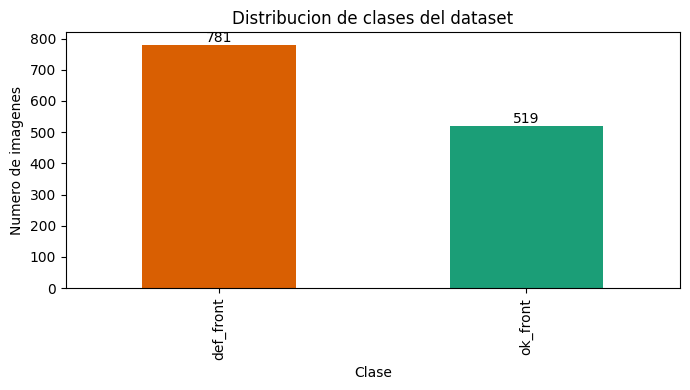

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind='bar', color=['#d95f02', '#1b9e77'], ax=ax)
ax.set(title='Distribucion de clases del dataset', xlabel='Clase', ylabel='Numero de imagenes')
ax.bar_label(ax.containers[0]); plt.tight_layout(); plt.show()

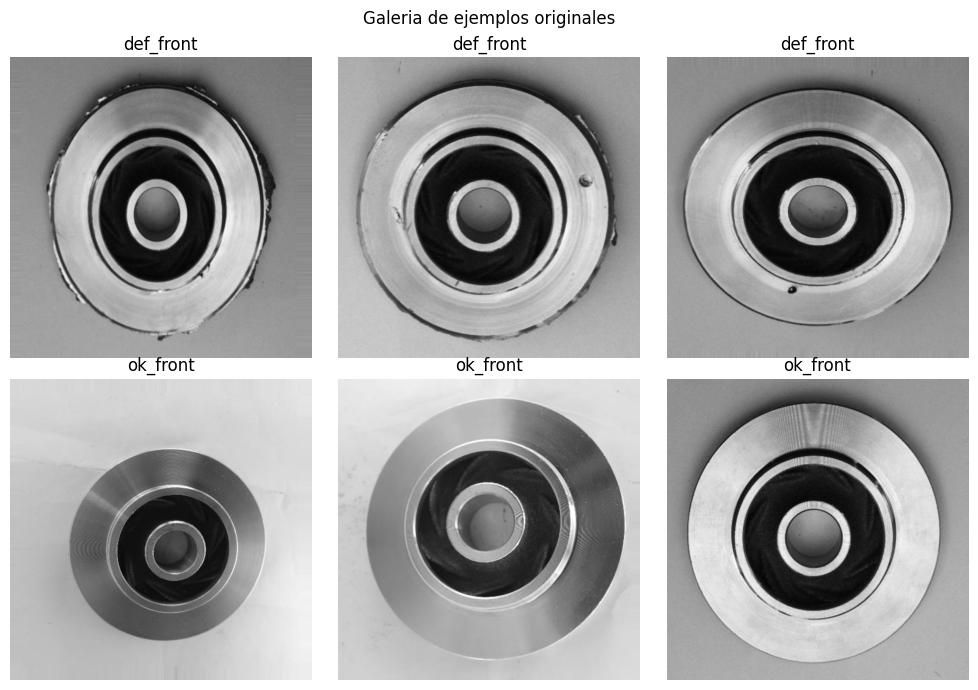

In [14]:
# Galeria equilibrada de ejemplos originales (sin modificar el dataset).
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(10, 7))
for row_i, class_name in enumerate(CLASSES):
    examples = eda.loc[eda.class_name == class_name, 'path'].head(3).tolist()
    for col_i, ax in enumerate(axes[row_i]):
        ax.axis('off')
        if col_i < len(examples):
            with Image.open(examples[col_i]) as image:
                ax.imshow(image.convert('RGB'))
            ax.set_title(class_name)
plt.suptitle('Galeria de ejemplos originales'); plt.tight_layout(); plt.show()


In [15]:
# Conclusiones calculadas, sin asumir balance ni dimensiones que no hayan sido observadas.
majority, minority = int(counts.max()), int(counts.min())
print('\nConclusiones EDA:')
print(f'- Desbalance mayoritaria/minoritaria: {majority}/{minority} = {majority/minority:.2f}:1.')
print(f'- Rango de dimensiones: {eda.width.min()}x{eda.height.min()} a {eda.width.max()}x{eda.height.max()}.')
print(f'- Rango de intensidad media: {eda.mean_intensity.min():.1f}-{eda.mean_intensity.max():.1f} (escala 0-255).')
if unreadable:
    print(f'- Se excluyeron {len(unreadable)} archivos ilegibles del inventario; no se borraron.')
print('- Se conserva RGB; normalizacion definida como float32 / 255, rango [0,1].')
print('- El notebook indica que la fuente ya contiene augmentation. Se parte primero train/validacion/test y la augmentation adicional queda restringida a train.')
print('- Revisar posibles imagenes casi duplicadas entre particiones antes del entrenamiento para prevenir leakage.')


Conclusiones EDA:
- Desbalance mayoritaria/minoritaria: 781/519 = 1.50:1.
- Rango de dimensiones: 512x512 a 512x512.
- Rango de intensidad media: 115.6-172.1 (escala 0-255).
- Se conserva RGB; normalizacion definida como float32 / 255, rango [0,1].
- El notebook indica que la fuente ya contiene augmentation. Se parte primero train/validacion/test y la augmentation adicional queda restringida a train.
- Revisar posibles imagenes casi duplicadas entre particiones antes del entrenamiento para prevenir leakage.


In [16]:
# Split estratificado 70/15/15, semilla fija. La fuente permanece intacta.
train_df, remainder_df = train_test_split(eda, test_size=0.30, random_state=SEED, stratify=eda['label'])
val_df, test_df = train_test_split(remainder_df, test_size=0.50, random_state=SEED, stratify=remainder_df['label'])
splits = {'train': train_df.reset_index(drop=True), 'validation': val_df.reset_index(drop=True), 'test': test_df.reset_index(drop=True)}

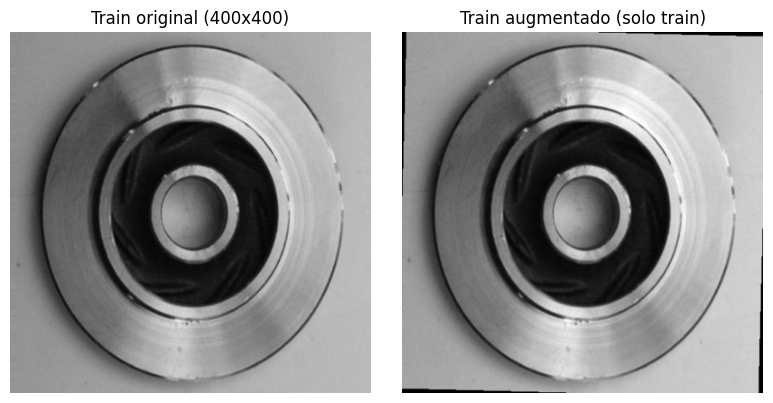

In [17]:
# Previsualizar augmentation con una muestra de train: flip/rotacion/brillo.
from ml.preprocessing import preprocess_image, augment_training_image, make_tf_dataset
sample_path = splits['train'].iloc[0]['path']
original_preview = preprocess_image(sample_path)
augmented_preview = preprocess_image(augment_training_image(sample_path, seed=SEED))
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(original_preview); axes[0].set_title('Train original (400x400)')
axes[1].imshow(augmented_preview); axes[1].set_title('Train augmentado (solo train)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

In [18]:
# Guardar versiones RGB 400x400 y manifiesto bajo la ruta solicitada.
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
manifest_rows = []
for split_name, split_df in splits.items():
    for row in split_df.itertuples(index=False):
        target = PROCESSED_DIR / split_name / row.class_name / f'{row.path.stem}.jpg'
        target.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(row.path) as image:
            image.convert('RGB').resize(TARGET_SIZE, Image.Resampling.BILINEAR).save(target, 'JPEG', quality=95, optimize=True)
        manifest_rows.append({'path': target.relative_to(ROOT).as_posix(), 'split': split_name,
                              'class_name': row.class_name, 'label_defect': int(row.label), 'sample_type': 'original'})

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(PROCESSED_DIR / 'manifest.csv', index=False)
eda.drop(columns=['path']).to_csv(PROCESSED_DIR / 'eda_image_stats.csv', index=False)

In [19]:
# Verificacion de tamaño final de todos los ejemplos exportados.
for path in PROCESSED_DIR.glob('*/*/*'):
    if path.is_file() and path.suffix.lower() == '.jpg':
        with Image.open(path) as image:
            if image.size != TARGET_SIZE:
                raise AssertionError(f'Tamano inesperado: {path} -> {image.size}')
print('\nParticiones procesadas (solo originales; augmentation se aplica al generador de train):')
display(manifest.groupby(['split', 'class_name']).size().rename('imagenes').to_frame())
print(f'Imagenes procesadas: {len(manifest)} | Todas con tamano {TARGET_SIZE[0]}x{TARGET_SIZE[1]} | Carpeta: {PROCESSED_DIR}')


Particiones procesadas (solo originales; augmentation se aplica al generador de train):


imagenes
split      class_name          
test       def_front        117
           ok_front          78
train      def_front        547
           ok_front         363
validation def_front        117
           ok_front          78

Imagenes procesadas: 1300 | Todas con tamano 400x400 | Carpeta: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/data/processed_data_400x400


In [20]:
# Crear un batch para demostrar el generador; el argumento training=True activa flip/rotacion/brillo.
train_paths = [ROOT / p for p in manifest.loc[manifest.split == 'train', 'path']]
train_labels = manifest.loc[manifest.split == 'train', 'label_defect'].to_numpy()
val_paths = [ROOT / p for p in manifest.loc[manifest.split == 'validation', 'path']]
val_labels = manifest.loc[manifest.split == 'validation', 'label_defect'].to_numpy()
train_batch_images, train_batch_labels = next(iter(make_tf_dataset(train_paths, train_labels, training=True, batch_size=8, seed=SEED)))
val_batch_images, val_batch_labels = next(iter(make_tf_dataset(val_paths, val_labels, training=False, batch_size=8, seed=SEED)))
assert tuple(train_batch_images.shape[1:]) == (400, 400, 3) and tuple(val_batch_images.shape[1:]) == (400, 400, 3)
print(f'Generador train: {train_batch_images.shape}; generador validation sin augmentation: {val_batch_images.shape}.')

Generador train: (8, 400, 400, 3); generador validation sin augmentation: (8, 400, 400, 3).


In [21]:
# DVC ya rastrea la carpeta data completa mediante data.dvc; refrescar el puntero mantiene raw + processed en un solo output.
remote_list = subprocess.check_output(['dvc', 'remote', 'list'], cwd=ROOT, text=True)
if not any(line.split() and line.split()[0] == 'drive' for line in remote_list.splitlines()):
    raise RuntimeError('No esta configurado el remoto DVC drive; no se modifica el puntero.')
subprocess.run(['dvc', 'add', 'data'], cwd=ROOT, check=True)
subprocess.run(['dvc', 'push', 'data.dvc'], cwd=ROOT, check=True)
# Dejar listos para revision el notebook, el modulo y el puntero. No se crea commit ni se hace push a GitHub.
subprocess.run(['git', 'add', 'RIKUY_DEEP_G2.ipynb', 'ml/preprocessing.py', 'data.dvc', '.gitignore'], cwd=ROOT, check=True)
print('\nVersion DVC enviada al remoto Google Drive. Cambios Git preparados, sin commit ni push:')
print(subprocess.check_output(['git', 'status', '--short', '--branch'], cwd=ROOT, text=True))


Version DVC enviada al remoto Google Drive. Cambios Git preparados, sin commit ni push:
## RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados...origin/RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados
M  RIKUY_DEEP_G2.ipynb
?? ml/__pycache__/



## Entrenando el dataset con un CNN

Distribución total por clase:


,,n
class_name,label_defect,
def_front,1,781
ok_front,0,519


Train por etiqueta: {0: 363, 1: 547} | pesos equilibrados: {0: 1.2534435261707988, 1: 0.8318098720292505}
Train/validación/test: 910 195 195 | razón global 781:519 = 1.50:1


Model: "cnn_baseline_hu10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 400, 400, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 400, 400, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 400, 400, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 200, 200, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 200, 200, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 200, 200, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 200, 200, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 100, 100, 128)  │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100, 100, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 100, 100, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 50, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,529 (1009.88 KB)

 Trainable params: 257,825 (1007.13 KB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/35
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.6680 - auc_pr: 0.8299 - auc_roc: 0.7359 - loss: 0.6017 - precision: 0.7514 - recall: 0.6884
Epoch 1: val_auc_pr improved from None to 0.84530, saving model to /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_20261031T183456Z/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_20261031T183456Z/best_model.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 49s 458ms/step - accuracy: 0.7231 - auc_pr: 0.8582 - auc_roc: 0.7814 - loss: 0.5615 - precision: 0.8118 - recall: 0.7020 - val_accuracy: 0.4000 - val_auc_pr: 0.8453 - val_auc_roc: 0.8171 - val_loss: 1.1330 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/35
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.7305 - auc_pr: 0.8762 - auc_roc: 0.8069 - loss: 0.5349 - precision: 0.8227 - recall: 0.7060
Epoch 2: val_auc_pr improved from 

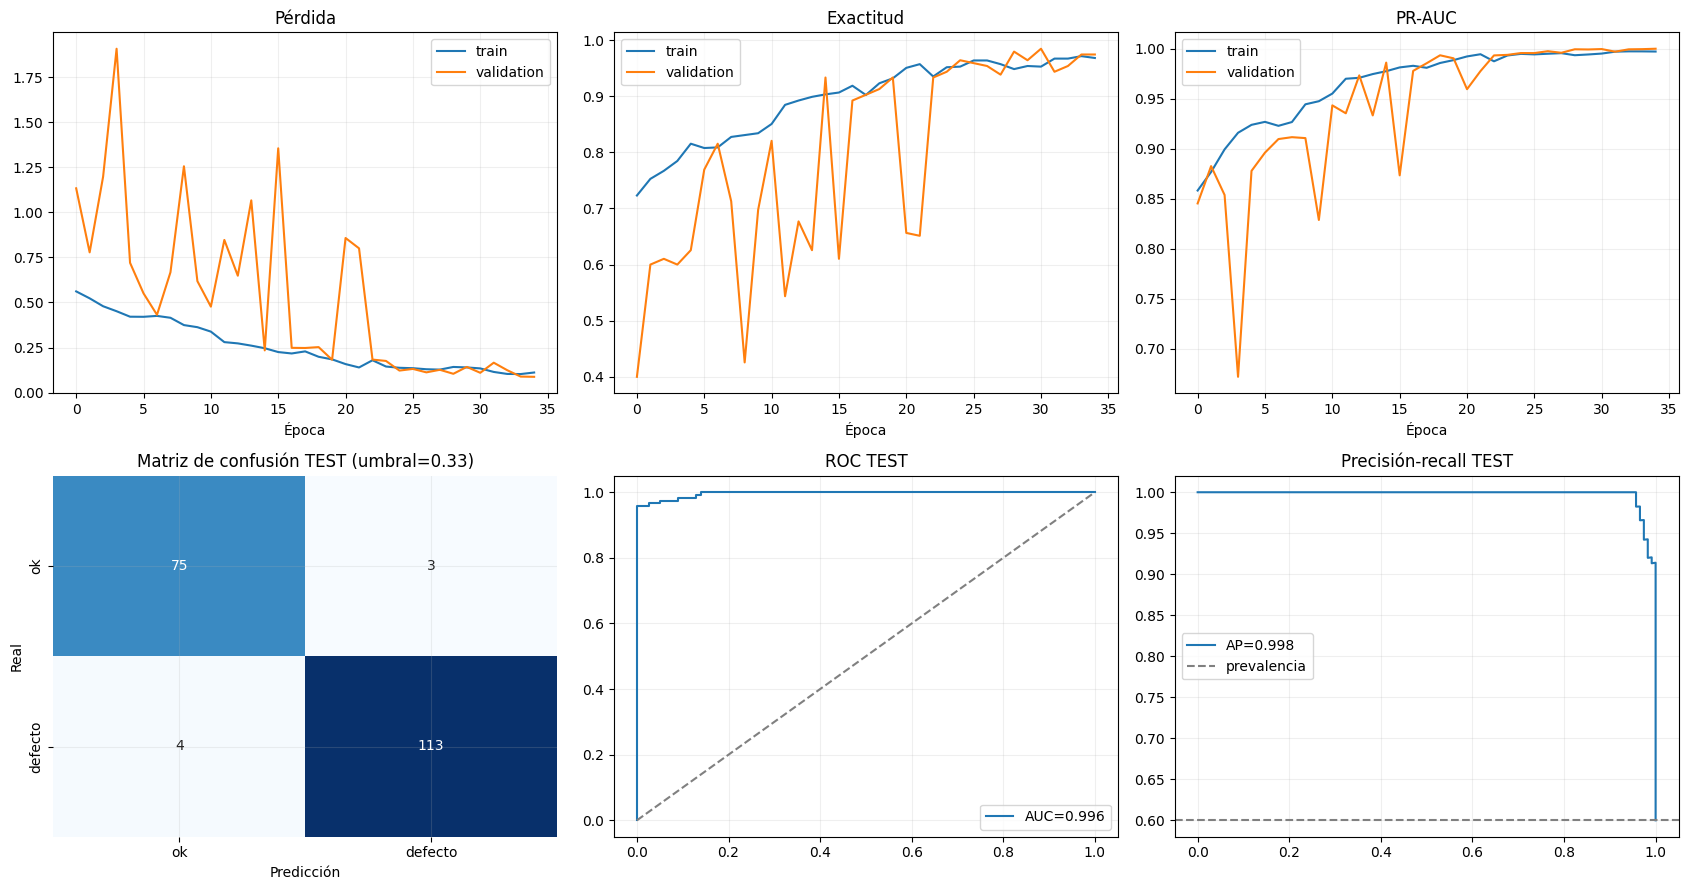


Modelo y registro guardados en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_20261031T183456Z
No se hizo commit ni push a GitHub. Revisa las curvas y la matriz antes de decidir próximos ajustes.


In [24]:
# HU10 — CNN base para inspección. Sin augmentation extra: el dataset fuente ya viene augmentado.
import json, subprocess, hashlib
from datetime import datetime, timezone
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, precision_recall_curve, f1_score,
                             accuracy_score, brier_score_loss)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

HU10_BRANCH = 'RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados'
assert branch == HU10_BRANCH, f'Rama incorrecta: {branch}'
HU10_RUN_ID = datetime.now(timezone.utc).strftime('cnn_baseline_%Y%m%dT%H%M%SZ')
HU10_OUT = ROOT / 'models' / 'cnn_baseline' / HU10_RUN_ID
HU10_OUT.mkdir(parents=True, exist_ok=True)

# Validar manifiesto, particiones y distribución; pesos calculados solo con train.
manifest_hu10 = pd.read_csv(PROCESSED_DIR / 'manifest.csv')
required = {'path', 'split', 'class_name', 'label_defect'}
assert required.issubset(manifest_hu10.columns), f'Faltan columnas: {required - set(manifest_hu10.columns)}'
assert set(manifest_hu10['split']) == {'train', 'validation', 'test'}
assert set(manifest_hu10['class_name']) == set(CLASSES)
assert manifest_hu10.groupby('path')['split'].nunique().max() == 1, 'Hay rutas compartidas entre particiones.'
manifest_hu10['abs_path'] = manifest_hu10['path'].map(lambda p: ROOT / p)
assert all(p.is_file() for p in manifest_hu10['abs_path']), 'Faltan imágenes de la partición procesada.'
assert manifest_hu10.groupby('class_name')['label_defect'].nunique().max() == 1
train_hu10 = manifest_hu10[manifest_hu10.split == 'train'].copy()
val_hu10 = manifest_hu10[manifest_hu10.split == 'validation'].copy()
test_hu10 = manifest_hu10[manifest_hu10.split == 'test'].copy()
counts_train = train_hu10['label_defect'].value_counts().sort_index()
weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=train_hu10['label_defect'].to_numpy())
class_weight_hu10 = {int(c): float(w) for c, w in zip([0, 1], weights)}
print('Distribución total por clase:')
display(manifest_hu10.groupby(['class_name','label_defect']).size().rename('n').to_frame())
print('Train por etiqueta:', counts_train.to_dict(), '| pesos equilibrados:', class_weight_hu10)
print('Train/validación/test:', len(train_hu10), len(val_hu10), len(test_hu10), '| razón global 781:519 = 1.50:1')

# RGB bilinear 400x400 y normalización [0,1], igual que HU06.
IMG_SIZE = (400, 400)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
def hu10_dataset(frame, training=False):
    paths = frame['abs_path'].map(str).to_numpy()
    labels = frame['label_defect'].astype('float32').to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    def decode(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE, method='bilinear')
        image = tf.cast(image, tf.float32) / 255.0
        return image, label
    return ds.map(decode, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
train_ds_hu10 = hu10_dataset(train_hu10, training=True)
val_ds_hu10 = hu10_dataset(val_hu10)
test_ds_hu10 = hu10_dataset(test_hu10)

# CNN entrenada desde cero; una salida sigmoide estima P(defecto).
tf.keras.utils.set_random_seed(SEED)
with tf.device('/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'):
    model_hu10 = models.Sequential([
        layers.Input(shape=(400, 400, 3)),
        layers.Conv2D(32, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding='same', use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(), layers.Dense(128, activation='relu'), layers.Dropout(0.35), layers.Dense(1, activation='sigmoid')
    ], name='cnn_baseline_hu10')
    model_hu10.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'), tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc_roc'),
                 tf.keras.metrics.AUC(name='auc_pr', curve='PR')])
model_hu10.summary()

best_path_hu10 = HU10_OUT / 'best_model.keras'
callbacks_hu10 = [
    ModelCheckpoint(str(best_path_hu10), monitor='val_auc_pr', mode='max', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_auc_pr', mode='max', patience=7, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    CSVLogger(str(HU10_OUT / 'training_history.csv'))
]
history_hu10 = model_hu10.fit(train_ds_hu10, validation_data=val_ds_hu10, epochs=35,
    class_weight=class_weight_hu10, callbacks=callbacks_hu10, verbose=1)

# Umbral elegido en validación por F1; test queda reservado para evaluación final.
model_hu10 = tf.keras.models.load_model(best_path_hu10)
y_val = val_hu10['label_defect'].to_numpy().astype(int)
p_val = model_hu10.predict(val_ds_hu10, verbose=0).ravel()
prec, rec, thresholds = precision_recall_curve(y_val, p_val)
f1_values = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
threshold_hu10 = float(thresholds[int(np.argmax(f1_values))]) if len(thresholds) else 0.5

y_test = test_hu10['label_defect'].to_numpy().astype(int)
p_test = model_hu10.predict(test_ds_hu10, verbose=0).ravel()
y_pred = (p_test >= threshold_hu10).astype(int)
report_hu10 = classification_report(y_test, y_pred, target_names=['ok_front (0)', 'def_front (1)'], output_dict=True, zero_division=0)
cm_hu10 = confusion_matrix(y_test, y_pred, labels=[0,1])
metrics_hu10 = {
    'test_accuracy': float(accuracy_score(y_test, y_pred)),
    'test_roc_auc': float(roc_auc_score(y_test, p_test)),
    'test_average_precision': float(average_precision_score(y_test, p_test)),
    'test_brier': float(brier_score_loss(y_test, p_test)),
    'validation_threshold_f1': threshold_hu10,
    'validation_best_f1': float(np.max(f1_values)) if len(f1_values) else None,
    'test_classification_report': report_hu10,
    'test_confusion_matrix_labels_0_1': cm_hu10.tolist(),
    'best_epoch': int(np.argmax(history_hu10.history['val_auc_pr']) + 1),
    'epochs_ran': len(history_hu10.history['loss'])
}
print('\nReporte final en TEST (umbral elegido únicamente con validation):')
print(classification_report(y_test, y_pred, target_names=['ok_front (0)', 'def_front (1)'], zero_division=0))
print('Métricas:', json.dumps({k:v for k,v in metrics_hu10.items() if k != 'test_classification_report'}, indent=2))

# Gráficas para revisar ajuste, matriz de confusión y ranking de defectos.
hist = pd.DataFrame(history_hu10.history)
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, metric, title in zip(axes[0], ['loss','accuracy','auc_pr'], ['Pérdida','Exactitud','PR-AUC']):
    ax.plot(hist[metric], label='train'); ax.plot(hist['val_'+metric], label='validation'); ax.set_title(title); ax.set_xlabel('Época'); ax.legend()
sns.heatmap(cm_hu10, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1,0], xticklabels=['ok','defecto'], yticklabels=['ok','defecto'])
axes[1,0].set_title(f'Matriz de confusión TEST (umbral={threshold_hu10:.2f})'); axes[1,0].set_xlabel('Predicción'); axes[1,0].set_ylabel('Real')
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1,1].plot(fpr,tpr,label=f'AUC={metrics_hu10["test_roc_auc"]:.3f}'); axes[1,1].plot([0,1],[0,1],'--',color='gray'); axes[1,1].set_title('ROC TEST'); axes[1,1].legend()
p_test_curve, r_test_curve, _ = precision_recall_curve(y_test,p_test)
axes[1,2].plot(r_test_curve,p_test_curve,label=f'AP={metrics_hu10["test_average_precision"]:.3f}'); axes[1,2].axhline(y_test.mean(),ls='--',color='gray',label='prevalencia'); axes[1,2].set_title('Precisión-recall TEST'); axes[1,2].legend()
for ax in axes.flat: ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(HU10_OUT / 'evaluation_plots.png', dpi=150, bbox_inches='tight'); plt.show()

experiment_hu10 = dict(
    run_id=HU10_RUN_ID, created_utc=datetime.now(timezone.utc).isoformat(),
    branch=branch, model='CNN from scratch, binary sigmoid', input_shape=[400,400,3],
    normalization='RGB float32 / 255 -> [0,1]', augmentation_during_training=False,
    dataset_note='Fuente ya augmentada según diseño del notebook; sin augmentation extra.',
    total_class_distribution=json.loads(manifest_hu10.class_name.value_counts().to_json()),
    train_label_distribution={str(k): int(v) for k,v in counts_train.items()},
    class_weight=class_weight_hu10, batch_size=BATCH_SIZE, seed=SEED,
    optimizer='Adam', initial_learning_rate=1e-3, max_epochs=35,
    metrics=metrics_hu10, tensorflow=tf.__version__,
    gpu=[d.name for d in tf.config.list_physical_devices('GPU')]
)
(HU10_OUT / 'experiment.json').write_text(json.dumps(experiment_hu10, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'\nModelo y registro guardados en: {HU10_OUT}')
print('No se hizo commit ni push a GitHub. Revisa las curvas y la matriz antes de decidir próximos ajustes.')


In [25]:
# Versionar el modelo, historial, graficas y experimento en el remoto DVC configurado (Google Drive).
model_dir = HU10_OUT.relative_to(ROOT)
subprocess.run(['dvc', 'add', str(model_dir)], cwd=ROOT, check=True)
pointer_hu10 = Path(str(model_dir) + '.dvc')
subprocess.run(['dvc', 'push', str(pointer_hu10)], cwd=ROOT, check=True)
# Preparar el puntero, .gitignore y notebook para revisión; no crear commit ni push a GitHub.
subprocess.run(['git', 'add', 'RIKUY_DEEP_G2.ipynb', str(pointer_hu10), '.gitignore'], cwd=ROOT, check=True)
print('DVC push completado al remoto configurado.')
print(subprocess.check_output(['git', 'status', '--short', '--branch'], cwd=ROOT, text=True))

DVC push completado al remoto configurado.
## RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados...origin/RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados
M  RIKUY_DEEP_G2.ipynb
A  models/cnn_baseline/cnn_baseline_20261031T183456Z.dvc
?? ml/__pycache__/
?? models/cnn_baseline/.gitignore



Train por clase: {'def_front': 547, 'ok_front': 363}
Pesos equilibrados aplicados: {0: 1.2534435261707988, 1: 0.8318098720292505}
Batch train augmentado: (16, 400, 400, 3) | rango: 0.0 1.0
Epoch 1/35
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.6221 - auc_pr: 0.7530 - auc_roc: 0.6539 - loss: 0.6681 - precision: 0.7099 - recall: 0.6543
Epoch 1: val_auc_pr improved from None to 0.81474, saving model to /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_aug_20261031T185054Z/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_aug_20261031T185054Z/best_model.keras
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 437ms/step - accuracy: 0.6341 - auc_pr: 0.7478 - auc_roc: 0.6858 - loss: 0.6539 - precision: 0.7286 - recall: 0.6234 - val_accuracy: 0.4000 - val_auc_pr: 0.8147 - val_auc_roc: 0.7891 - val_loss: 1.0262 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.

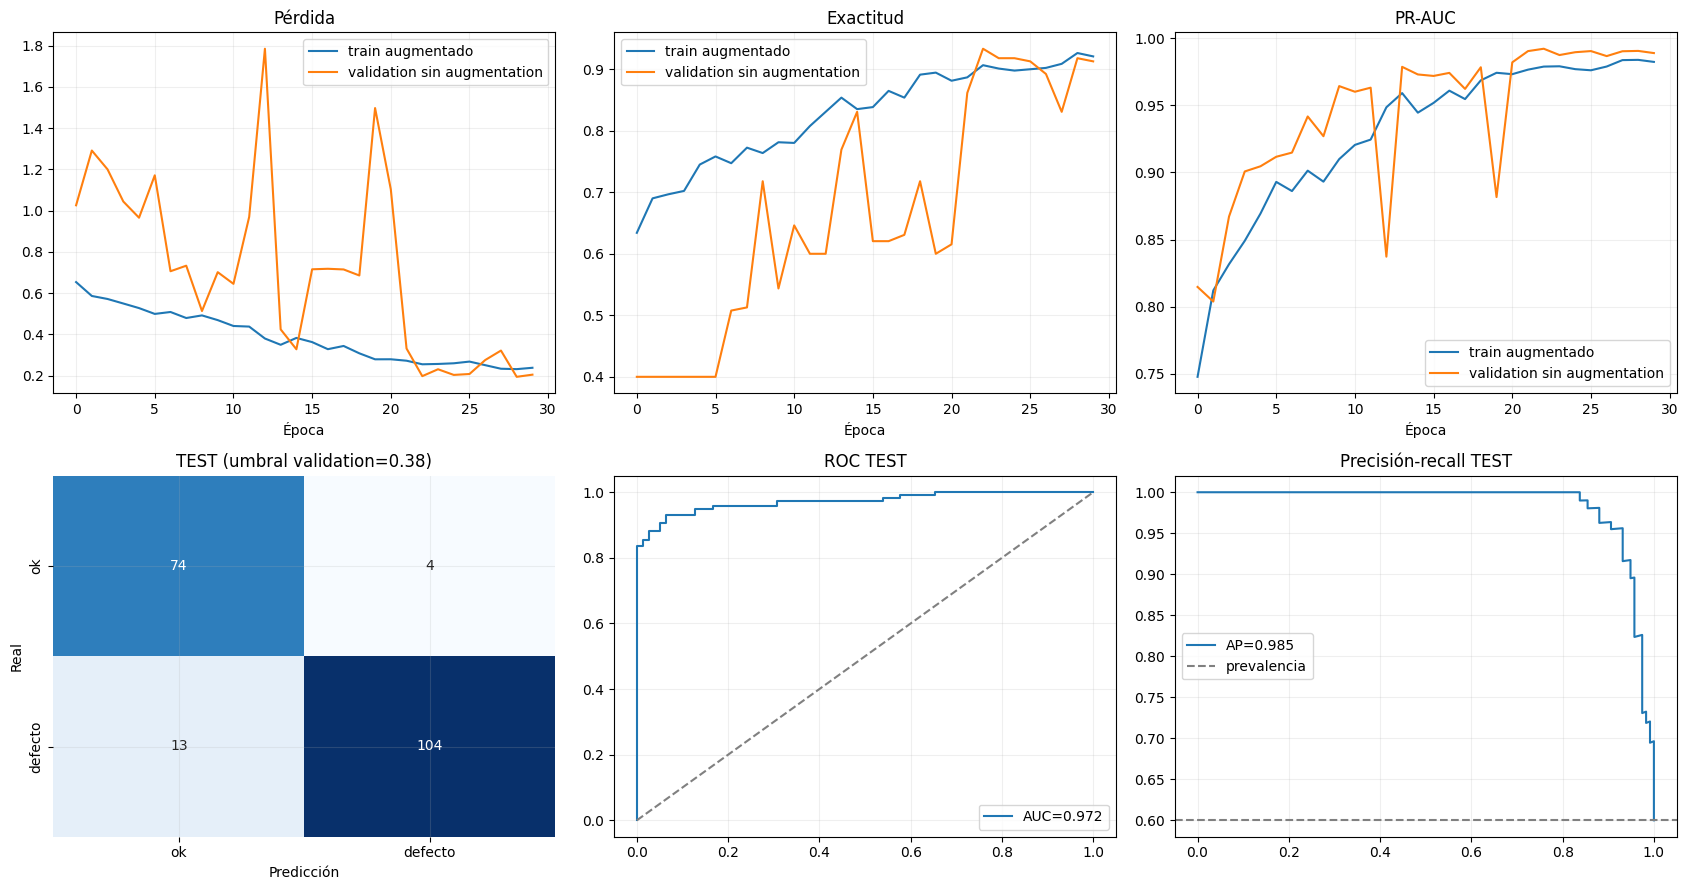

Artefactos guardados en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_aug_20261031T185054Z
DVC push de la corrida augmentada completado. Estado Git:
## RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados...origin/RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados
M  RIKUY_DEEP_G2.ipynb
A  models/cnn_baseline/.gitignore
A  models/cnn_baseline/cnn_baseline_20261031T183456Z.dvc
A  models/cnn_baseline/cnn_baseline_aug_20261031T185054Z.dvc
?? ml/__pycache__/



In [27]:
# HU10 — reentrenamiento del baseline con augmentation on-the-fly solo en train.
# La función make_tf_dataset(training=True) de HU06 aplica flip, rotación y brillo.
# Validation/test permanecen sin augmentation. Se preserva la corrida anterior.
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
    roc_auc_score, average_precision_score, precision_recall_curve, brier_score_loss, roc_curve)
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from datetime import datetime, timezone
import json, subprocess

assert branch == HU10_BRANCH, f'Rama incorrecta: {branch}'
HU10_AUG_RUN_ID = datetime.now(timezone.utc).strftime('cnn_baseline_aug_%Y%m%dT%H%M%SZ')
HU10_AUG_OUT = ROOT / 'models' / 'cnn_baseline' / HU10_AUG_RUN_ID
HU10_AUG_OUT.mkdir(parents=True, exist_ok=True)
BATCH_SIZE_AUG = 16

# Recalcular balance exclusivamente con la distribución original de train.
y_train_aug = train_hu10['label_defect'].to_numpy().astype(int)
classes_aug = np.array([0, 1])
weights_aug = compute_class_weight(class_weight='balanced', classes=classes_aug, y=y_train_aug)
class_weight_aug = {int(k): float(v) for k, v in zip(classes_aug, weights_aug)}
print('Train por clase:', train_hu10.groupby('class_name').size().to_dict())
print('Pesos equilibrados aplicados:', class_weight_aug)

train_ds_aug = make_tf_dataset(
    train_hu10['abs_path'].tolist(), y_train_aug, training=True,
    batch_size=BATCH_SIZE_AUG, seed=SEED)
val_ds_aug = make_tf_dataset(
    val_hu10['abs_path'].tolist(), val_hu10['label_defect'].to_numpy(),
    training=False, batch_size=BATCH_SIZE_AUG, seed=SEED)
test_ds_aug = make_tf_dataset(
    test_hu10['abs_path'].tolist(), test_hu10['label_defect'].to_numpy(),
    training=False, batch_size=BATCH_SIZE_AUG, seed=SEED)

# Confirma visualmente que la augmentation está activa para train.
images_aug, labels_aug = next(iter(train_ds_aug))
print('Batch train augmentado:', images_aug.shape, '| rango:', float(tf.reduce_min(images_aug)), float(tf.reduce_max(images_aug)))

with tf.device('/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'):
    model_aug = models.Sequential([
        layers.Input(shape=(400,400,3)),
        layers.Conv2D(32,3,padding='same',use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.Conv2D(64,3,padding='same',use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.Conv2D(128,3,padding='same',use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.Conv2D(128,3,padding='same',use_bias=False), layers.BatchNormalization(), layers.Activation('relu'), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(), layers.Dense(128,activation='relu'), layers.Dropout(.35), layers.Dense(1,activation='sigmoid')
    ], name='cnn_baseline_hu10_augmented')
    model_aug.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'), tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc_roc'),
        tf.keras.metrics.AUC(name='auc_pr', curve='PR')])

best_aug_path = HU10_AUG_OUT / 'best_model.keras'
callbacks_aug = [
    ModelCheckpoint(str(best_aug_path), monitor='val_auc_pr', mode='max', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_auc_pr', mode='max', patience=7, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=.5, patience=3, min_lr=1e-6, verbose=1),
    CSVLogger(str(HU10_AUG_OUT / 'training_history.csv'))]
history_aug = model_aug.fit(train_ds_aug, validation_data=val_ds_aug, epochs=35,
    class_weight=class_weight_aug, callbacks=callbacks_aug, verbose=1)
model_aug = tf.keras.models.load_model(best_aug_path)



Reporte final TEST — CNN augmentada:
               precision    recall  f1-score   support

 ok_front (0)       0.85      0.95      0.90        78
def_front (1)       0.96      0.89      0.92       117

     accuracy                           0.91       195
    macro avg       0.91      0.92      0.91       195
 weighted avg       0.92      0.91      0.91       195

Métricas: {
  "test_accuracy": 0.9128205128205128,
  "test_roc_auc": 0.9721674337058951,
  "test_average_precision": 0.9846999229617102,
  "test_brier": 0.06600398782287316,
  "validation_threshold_f1": 0.3849126100540161,
  "validation_best_f1": 0.9531914893617022,
  "confusion_matrix_0_1": [
    [
      74,
      4
    ],
    [
      13,
      104
    ]
  ],
  "best_epoch": 23,
  "epochs_ran": 30
}


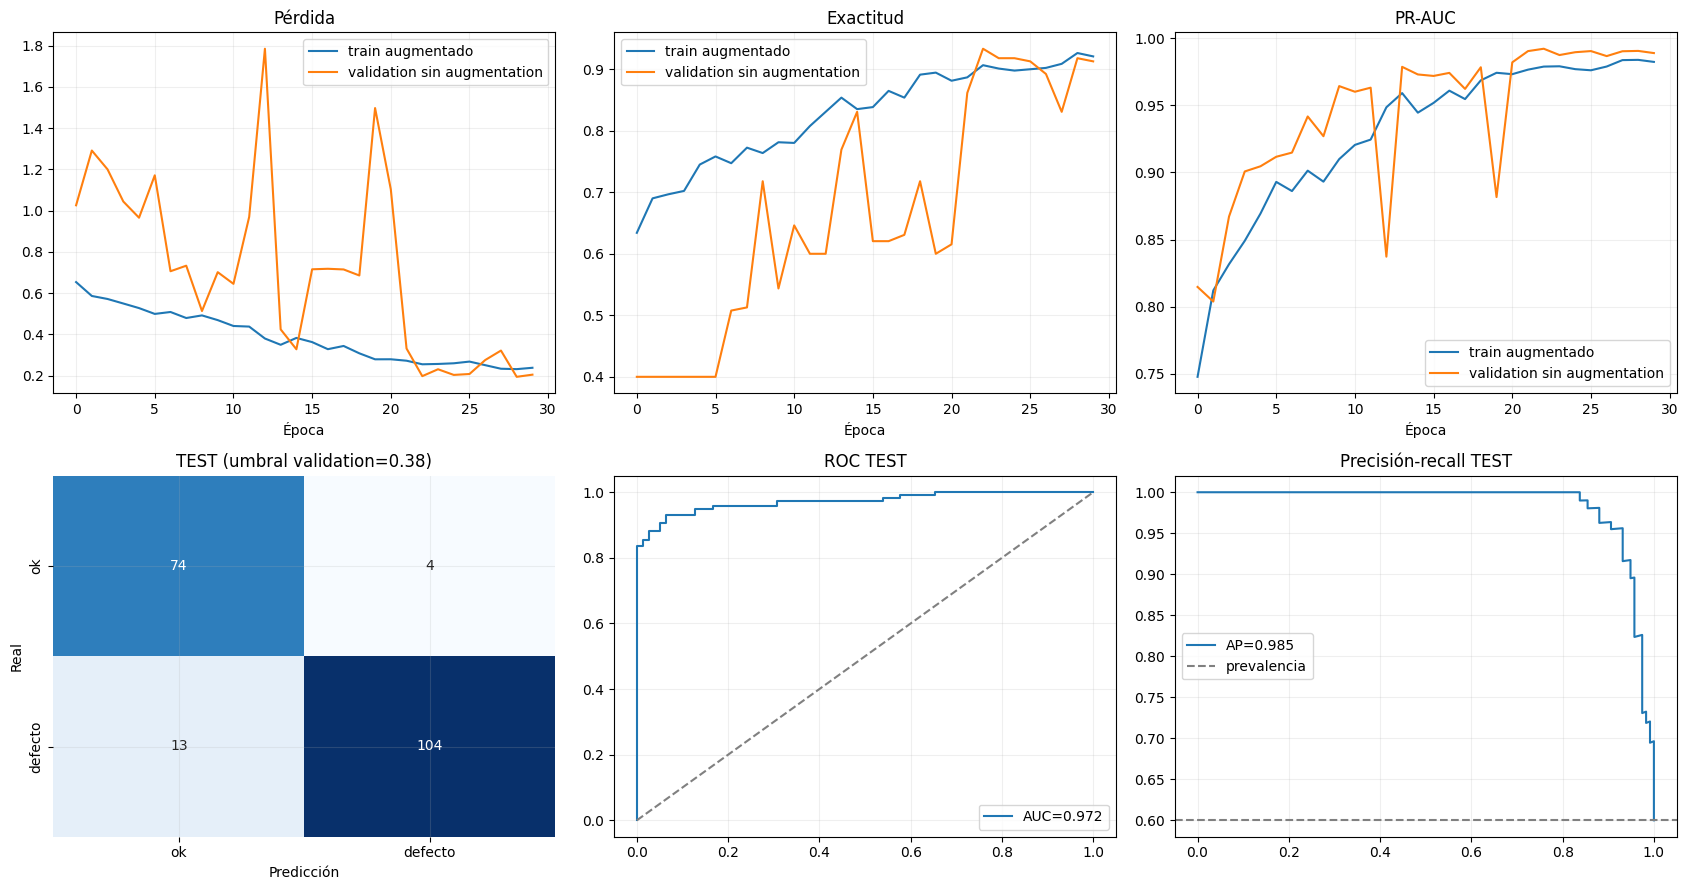

Artefactos guardados en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/cnn_baseline/cnn_baseline_aug_20261031T185054Z
DVC push de la corrida augmentada completado. Estado Git:
## RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados...origin/RIKDP-21-HU10-Entrenar-el-modelo-base-con-datos-validados-y-experimentos-registrados
M  RIKUY_DEEP_G2.ipynb
A  models/cnn_baseline/.gitignore
A  models/cnn_baseline/cnn_baseline_20261031T183456Z.dvc
A  models/cnn_baseline/cnn_baseline_aug_20261031T185054Z.dvc
?? ml/__pycache__/



In [28]:
# Umbral se decide en validation; test se usa solo para el reporte final de esta corrida.
y_val_aug = val_hu10['label_defect'].to_numpy().astype(int)
p_val_aug = model_aug.predict(val_ds_aug, verbose=0).ravel()
pr, rc, th = precision_recall_curve(y_val_aug, p_val_aug)
f1v = 2*pr[:-1]*rc[:-1]/np.maximum(pr[:-1]+rc[:-1],1e-12)
threshold_aug = float(th[int(np.argmax(f1v))]) if len(th) else .5
y_test_aug = test_hu10['label_defect'].to_numpy().astype(int)
p_test_aug = model_aug.predict(test_ds_aug, verbose=0).ravel()
y_pred_aug = (p_test_aug >= threshold_aug).astype(int)
cm_aug = confusion_matrix(y_test_aug, y_pred_aug, labels=[0,1])
report_aug = classification_report(y_test_aug, y_pred_aug, target_names=['ok_front (0)','def_front (1)'], zero_division=0, output_dict=True)
metrics_aug = dict(test_accuracy=float(accuracy_score(y_test_aug,y_pred_aug)),
    test_roc_auc=float(roc_auc_score(y_test_aug,p_test_aug)),
    test_average_precision=float(average_precision_score(y_test_aug,p_test_aug)),
    test_brier=float(brier_score_loss(y_test_aug,p_test_aug)),
    validation_threshold_f1=threshold_aug, validation_best_f1=float(np.max(f1v)),
    confusion_matrix_0_1=cm_aug.tolist(), classification_report=report_aug,
    best_epoch=int(np.argmax(history_aug.history['val_auc_pr'])+1), epochs_ran=len(history_aug.history['loss']))
print('\nReporte final TEST — CNN augmentada:')
print(classification_report(y_test_aug,y_pred_aug,target_names=['ok_front (0)','def_front (1)'],zero_division=0))
print('Métricas:', json.dumps({k:v for k,v in metrics_aug.items() if k!='classification_report'},indent=2))

hist_aug = pd.DataFrame(history_aug.history)
fig, axes = plt.subplots(2,3,figsize=(17,9))
for ax,metric,title in zip(axes[0],['loss','accuracy','auc_pr'],['Pérdida','Exactitud','PR-AUC']):
    ax.plot(hist_aug[metric],label='train augmentado'); ax.plot(hist_aug['val_'+metric],label='validation sin augmentation'); ax.set_title(title); ax.set_xlabel('Época'); ax.legend()
sns.heatmap(cm_aug,annot=True,fmt='d',cmap='Blues',cbar=False,ax=axes[1,0],xticklabels=['ok','defecto'],yticklabels=['ok','defecto'])
axes[1,0].set_title(f'TEST (umbral validation={threshold_aug:.2f})'); axes[1,0].set_xlabel('Predicción'); axes[1,0].set_ylabel('Real')
fpr_aug,tpr_aug,_=roc_curve(y_test_aug,p_test_aug)
axes[1,1].plot(fpr_aug,tpr_aug,label=f'AUC={metrics_aug["test_roc_auc"]:.3f}'); axes[1,1].plot([0,1],[0,1],'--',color='gray'); axes[1,1].set_title('ROC TEST'); axes[1,1].legend()
pr_test_aug,rc_test_aug,_=precision_recall_curve(y_test_aug,p_test_aug)
axes[1,2].plot(rc_test_aug,pr_test_aug,label=f'AP={metrics_aug["test_average_precision"]:.3f}'); axes[1,2].axhline(y_test_aug.mean(),ls='--',color='gray',label='prevalencia'); axes[1,2].set_title('Precisión-recall TEST'); axes[1,2].legend()
for ax in axes.flat: ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(HU10_AUG_OUT/'evaluation_plots.png',dpi=150,bbox_inches='tight'); plt.show()

exp_aug = dict(run_id=HU10_AUG_RUN_ID, created_utc=datetime.now(timezone.utc).isoformat(), branch=branch,
    model='CNN from scratch; augmentation solo en train', input_shape=[400,400,3],
    augmentation='flip horizontal, rotación y brillo con make_tf_dataset(training=True)',
    validation_test_augmentation=False, train_distribution=train_hu10.groupby('class_name').size().to_dict(),
    class_weight=class_weight_aug, batch_size=BATCH_SIZE_AUG, seed=SEED,
    optimizer='Adam', initial_learning_rate=1e-3, metrics=metrics_aug,
    tensorflow=tf.__version__, gpu=[d.name for d in tf.config.list_physical_devices('GPU')])
(HU10_AUG_OUT/'experiment.json').write_text(json.dumps(exp_aug,indent=2,ensure_ascii=False),encoding='utf-8')
print('Artefactos guardados en:', HU10_AUG_OUT)

# Versionar esta corrida en el remoto DVC (Google Drive); dejar puntero para revisión, sin commit/push GitHub.
aug_rel = HU10_AUG_OUT.relative_to(ROOT)
subprocess.run(['dvc','add',str(aug_rel)],cwd=ROOT,check=True)
aug_pointer = Path(str(aug_rel)+'.dvc')
subprocess.run(['dvc','push',str(aug_pointer)],cwd=ROOT,check=True)
subprocess.run(['git','add','RIKUY_DEEP_G2.ipynb',str(aug_pointer),'models/cnn_baseline/.gitignore','.gitignore'],cwd=ROOT,check=True)
print('DVC push de la corrida augmentada completado. Estado Git:')
print(subprocess.check_output(['git','status','--short','--branch'],cwd=ROOT,text=True))

## Aplicando Transfer learning (MobileNetV2)

2026/10/31 20:29:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/31 20:29:01 INFO mlflow.store.db.utils: Updating database tables


Clases train: {'def_front': 547, 'ok_front': 363} | pesos: {0: 1.2534435261707988, 1: 0.8318098720292505} | GPU: ['/physical_device:GPU:0']


/tmp/ipykernel_3340/731763205.py:37: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base=tf.keras.applications.MobileNetV2(include_top=False,weights='imagenet',input_shape=(400,400,3)); base.trainable=True


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
57/57 - 50s - 875ms/step - accuracy: 0.7330 - auc_pr: 0.8867 - auc_roc: 0.8216 - loss: 0.5076 - val_accuracy: 0.8410 - val_auc_pr: 0.9844 - val_auc_roc: 0.9762 - val_loss: 0.3432 - learning_rate: 1.0000e-04
Epoch 2/10
57/57 - 16s - 272ms/step - accuracy: 0.8901 - auc_pr: 0.9799 - auc_roc: 0.9686 - loss: 0.2429 - val_accuracy: 0.9897 - val_auc_pr: 0.9990 - val_auc_roc: 0.9983 - val_loss: 0.0840 - learning_rate: 1.0000e-04
Epoch 3/10
57/57 - 20s - 356ms/step - accuracy: 0.9527 - auc_pr: 0.9951 - auc_roc: 0.9920 - loss: 0.1203 - val_accuracy: 0.9744 - val_auc_pr: 0.9993 - val_auc_roc: 0.9988 - val_loss: 0.0777 - learning_rate: 1.0000e-04
Epoch 4/10
57/57 - 21s - 360ms/step - accuracy: 0.9846 - auc_pr: 0.9987 - auc_roc: 0.9980 - loss: 0.0584 - val_accuracy: 0.9897 - val_auc_pr: 0.9995 - val_auc_roc: 0.9992 - val_loss: 0.0361 - learning_rate: 1.0000e-04
Epoch 5/10
57/57 - 15s - 266ms/step - accuracy: 0.9868 - auc_pr: 0.9994 - auc_r

/tmp/ipykernel_3340/731763205.py:37: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base=tf.keras.applications.MobileNetV2(include_top=False,weights='imagenet',input_shape=(400,400,3)); base.trainable=True


...

Epoch 1/10
57/57 - 40s - 708ms/step - accuracy: 0.7000 - auc_pr: 0.8422 - auc_roc: 0.7731 - loss: 0.5648 - val_accuracy: 0.8615 - val_auc_pr: 0.9868 - val_auc_roc: 0.9789 - val_loss: 0.3460 - learning_rate: 2.0000e-05
Epoch 2/10
57/57 - 22s - 392ms/step - accuracy: 0.8813 - auc_pr: 0.9727 - auc_roc: 0.9572 - loss: 0.2989 - val_accuracy: 0.8821 - val_auc_pr: 0.9939 - val_auc_roc: 0.9900 - val_loss: 0.2331 - learning_rate: 2.0000e-05
Epoch 3/10
57/57 - 16s - 285ms/step - accuracy: 0.9462 - auc_pr: 0.9929 - auc_roc: 0.9887 - loss: 0.1628 - val_accuracy: 0.9128 - val_auc_pr: 0.9971 - val_auc_roc: 0.9935 - val_loss: 0.2140 - learning_rate: 2.0000e-05
Epoch 4/10
57/57 - 16s - 283ms/step - accuracy: 0.9747 - auc_pr: 0.9972 - auc_roc: 0.9951 - loss: 0.1017 - val_accuracy: 0.9744 - val_auc_pr: 0.9986 - val_auc_roc: 0.9977 - val_loss: 0.1038 - learning_rate: 2.0000e-05
Epoch 5/10
57/57 - 15s - 272ms/step - accuracy: 0.9780 - auc_pr: 0.9980 - auc_roc: 0.9963 - loss: 0.0793 - val_accuracy: 0.9692 

/tmp/ipykernel_3340/731763205.py:37: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base=tf.keras.applications.MobileNetV2(include_top=False,weights='imagenet',input_shape=(400,400,3)); base.trainable=True


Epoch 1/10
57/57 - 45s - 784ms/step - accuracy: 0.6945 - auc_pr: 0.8563 - auc_roc: 0.7809 - loss: 0.5584 - val_accuracy: 0.8256 - val_auc_pr: 0.9550 - val_auc_roc: 0.9265 - val_loss: 0.3887 - learning_rate: 1.0000e-05
Epoch 2/10
57/57 - 17s - 302ms/step - accuracy: 0.8418 - auc_pr: 0.9569 - auc_roc: 0.9324 - loss: 0.3548 - val_accuracy: 0.9282 - val_auc_pr: 0.9924 - val_auc_roc: 0.9874 - val_loss: 0.2594 - learning_rate: 1.0000e-05
Epoch 3/10
57/57 - 21s - 367ms/step - accuracy: 0.8846 - auc_pr: 0.9755 - auc_roc: 0.9607 - loss: 0.2785 - val_accuracy: 0.9385 - val_auc_pr: 0.9968 - val_auc_roc: 0.9937 - val_loss: 0.1935 - learning_rate: 1.0000e-05
Epoch 4/10
57/57 - 20s - 360ms/step - accuracy: 0.9462 - auc_pr: 0.9937 - auc_roc: 0.9898 - loss: 0.1704 - val_accuracy: 0.9744 - val_auc_pr: 0.9972 - val_auc_roc: 0.9939 - val_loss: 0.1329 - learning_rate: 1.0000e-05
Epoch 5/10
57/57 - 17s - 304ms/step - accuracy: 0.9549 - auc_pr: 0.9964 - auc_roc: 0.9941 - loss: 0.1260 - val_accuracy: 0.9846 

,run_name,lr,fraction,dropout,best_val_auc_pr,val_average_precision,validation_threshold,val_recall,val_accuracy,meets_val_recall95
0,run01_lr1e-4_unfreeze15_drop30,0.00010,0.15,0.3,1.000000,1.000000,0.264899,1.000000,1.000000,True
1,run02_lr5e-5_unfreeze25_drop40,0.00005,0.25,0.4,1.000000,1.000000,0.110654,1.000000,1.000000,True
2,run03_lr2e-5_unfreeze35_drop30,0.00002,0.35,0.3,0.999581,0.999583,0.853059,0.991453,0.994872,True
3,run04_lr1e-5_unfreeze50_drop50,0.00001,0.50,0.5,0.998158,0.998210,0.404904,0.991453,0.994872,True


Reporte TEST (umbral elegido con validation):
               precision    recall  f1-score   support

 ok_front (0)       0.97      1.00      0.99        78
def_front (1)       1.00      0.98      0.99       117

     accuracy                           0.99       195
    macro avg       0.99      0.99      0.99       195
 weighted avg       0.99      0.99      0.99       195

{
  "selected_run": "run01_lr1e-4_unfreeze15_drop30",
  "threshold_selected_on_validation": 0.26489877700805664,
  "validation_recall": 1.0,
  "test_accuracy": 0.9897435897435898,
  "test_defect_recall": 0.9829059829059829,
  "test_defect_precision": 1.0,
  "test_f1": 0.9913793103448276,
  "test_roc_auc": 0.9994521148367301,
  "test_average_precision": 0.9996444029078062,
  "test_brier": 0.010035913824907539,
  "confusion_matrix_labels_0_ok_1_defect": [
    [
      78,
      0
    ],
    [
      2,
      115
    ]
  ],
  "hpo_runs": 4,
  "class_weights": {
    "0": 1.2534435261707988,
    "1": 0.8318098720292505
 

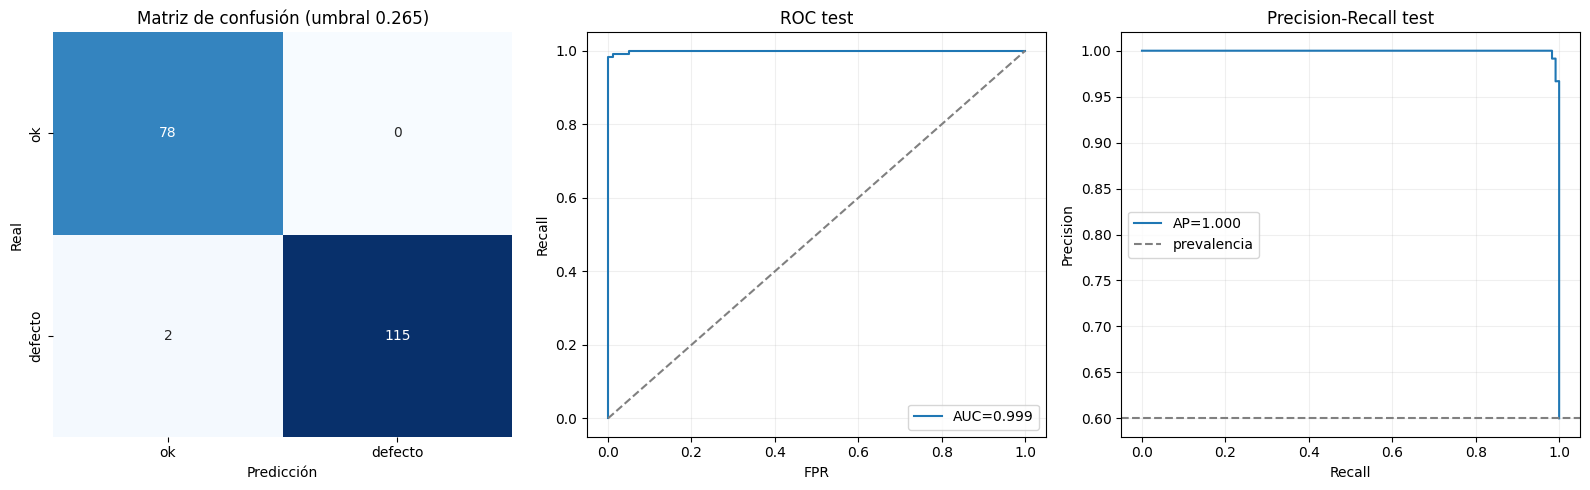

Falsos negativos: 2


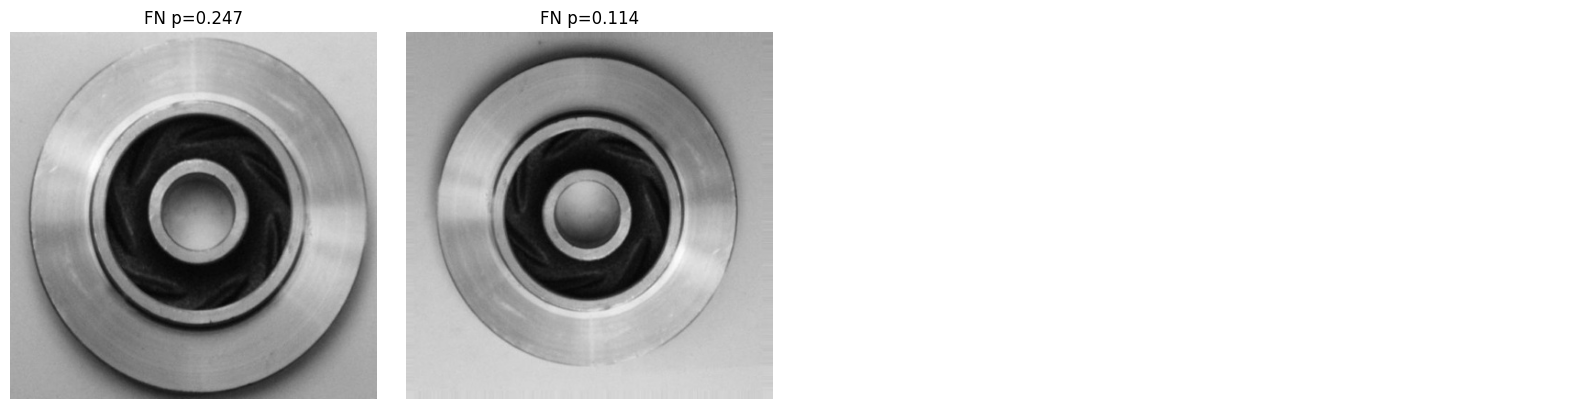

Artefactos: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/hu17_transfer_learning/mobilenetv2_hpo_20261031T202900Z
Cumple test (recall defectos >=95%, accuracy >=97%): True
DVC push completado; cambios listos para revisar, no se hizo commit ni push a GitHub.
## RIKDP-29-HU18-Evaluar-el-modelo-contra-la-métrica-objetivo...origin/RIKDP-29-HU18-Evaluar-el-modelo-contra-la-métrica-objetivo
M  RIKUY_DEEP_G2.ipynb
A  models/hu17_transfer_learning/mobilenetv2_hpo_20261031T202900Z.dvc
?? models/hu17_transfer_learning/.gitignore



In [54]:
# HU17: transfer learning, 4 corridas HPO y evaluación final
# Reutiliza el split fijo; augmentation solo en train; el umbral se decide en validation.
import os, sys, json, subprocess, importlib.util, shutil, gc
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from sklearn.metrics import (precision_recall_curve, classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, roc_curve, brier_score_loss)
from sklearn.utils.class_weight import compute_class_weight
for mod in list(sys.modules):
    if mod == 'mlflow' or mod.startswith('mlflow.') or mod == 'opentelemetry' or mod.startswith('opentelemetry.'):
        sys.modules.pop(mod, None)
import importlib
importlib.invalidate_caches()
import mlflow
HU17_BRANCH='RIKDP-29-HU18-Evaluar-el-modelo-contra-la-métrica-objetivo'
branch_hu17=subprocess.check_output(['git','branch','--show-current'],cwd=ROOT,text=True).strip()
assert branch_hu17==HU17_BRANCH, f'Rama incorrecta: {branch_hu17}'
assert all(v in globals() for v in ['train_hu10','val_hu10','test_hu10','train_ds_aug','val_ds_aug','test_ds_aug']), 'Ejecuta antes las celdas que crean split/datasets.'
STAMP_HU17=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT_HU17=ROOT/'models'/'hu17_transfer_learning'/f'mobilenetv2_hpo_{STAMP_HU17}'; OUT_HU17.mkdir(parents=True,exist_ok=True)
MLFLOW_DB=OUT_HU17/'mlflow.db'; mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')
EXP_NAME='RIKUY_HU17_MobileNetV2_HPO'
if mlflow.get_experiment_by_name(EXP_NAME) is None:
    mlflow.create_experiment(EXP_NAME,artifact_location=(OUT_HU17/'mlartifacts').as_uri())
mlflow.set_experiment(EXP_NAME)
ys=train_hu10['label_defect'].astype(int).to_numpy(); cwv=compute_class_weight('balanced',classes=np.array([0,1]),y=ys); CW_HU17={0:float(cwv[0]),1:float(cwv[1])}
print('Clases train:',train_hu10.groupby('class_name').size().to_dict(),'| pesos:',CW_HU17,'| GPU:',[d.name for d in tf.config.list_physical_devices('GPU')])
configs=[
 {'name':'run01_lr1e-4_unfreeze15_drop30','lr':1e-4,'fraction':.15,'dropout':.30},
 {'name':'run02_lr5e-5_unfreeze25_drop40','lr':5e-5,'fraction':.25,'dropout':.40},
 {'name':'run03_lr2e-5_unfreeze35_drop30','lr':2e-5,'fraction':.35,'dropout':.30},
 {'name':'run04_lr1e-5_unfreeze50_drop50','lr':1e-5,'fraction':.50,'dropout':.50}]
def build_hu17(c):
 inp=tf.keras.Input((400,400,3)); x=tf.keras.layers.Rescaling(2.,offset=-1.)(inp)
 base=tf.keras.applications.MobileNetV2(include_top=False,weights='imagenet',input_shape=(400,400,3)); base.trainable=True
 cutoff=len(base.layers)-int(np.ceil(len(base.layers)*c['fraction']))
 for i,l in enumerate(base.layers): l.trainable=(i>=cutoff and not isinstance(l,tf.keras.layers.BatchNormalization))
 x=base(x,training=False); x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dropout(c['dropout'])(x); out=tf.keras.layers.Dense(1,activation='sigmoid')(x)
 model=tf.keras.Model(inp,out,name='MobileNetV2_finetuned_HU17')
 model.compile(optimizer=tf.keras.optimizers.Adam(c['lr']),loss='binary_crossentropy',metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy'),tf.keras.metrics.AUC(curve='PR',name='auc_pr'),tf.keras.metrics.AUC(name='auc_roc')])
 return model,sum(l.trainable for l in base.layers),len(base.layers)
def choose_thr(y,p,target=.95):
 pr,rc,ths=precision_recall_curve(y,p)
 if not len(ths): return 0.,float(rc[0])
 valid=np.flatnonzero(rc[:-1]>=target)
 ix=int(valid[np.argmax(pr[valid])]) if len(valid) else int(np.argmax(rc[:-1]))
 return float(ths[ix]),float(rc[ix])
rows=[]
for c in configs:
 tf.keras.backend.clear_session(); gc.collect(); tf.keras.utils.set_random_seed(SEED)
 rdir=OUT_HU17/c['name']; rdir.mkdir(parents=True,exist_ok=True); ckpt=rdir/'best_model.keras'
 with mlflow.start_run(run_name=c['name']) as run:
  model,ntrain,ntotal=build_hu17(c)
  mlflow.log_params({'architecture':'MobileNetV2 ImageNet fine-tuning','learning_rate':c['lr'],'unfrozen_fraction':c['fraction'],'dropout':c['dropout'],'trainable_backbone_layers':ntrain,'total_backbone_layers':ntotal,'input':'400x400 RGB','augmentation':'train only','class_weight_0':CW_HU17[0],'class_weight_1':CW_HU17[1],'seed':int(SEED)})
  hist=model.fit(train_ds_aug,validation_data=val_ds_aug,epochs=10,class_weight=CW_HU17,verbose=2,callbacks=[
   tf.keras.callbacks.ModelCheckpoint(str(ckpt),monitor='val_auc_pr',mode='max',save_best_only=True),
   tf.keras.callbacks.EarlyStopping(monitor='val_auc_pr',mode='max',patience=2,restore_best_weights=True),
   tf.keras.callbacks.ReduceLROnPlateau(monitor='val_auc_pr',mode='max',factor=.5,patience=1,min_lr=1e-7),
   tf.keras.callbacks.CSVLogger(str(rdir/'history.csv'))])
  model=tf.keras.models.load_model(ckpt); yv=val_hu10.label_defect.astype(int).to_numpy(); pv=model.predict(val_ds_aug,verbose=0).ravel(); thr,rc=choose_thr(yv,pv)
  pred=(pv>=thr).astype(int); row={'run_name':c['name'],'run_id':run.info.run_id,**c,'trainable_backbone_layers':ntrain,
   'best_val_auc_pr':float(max(hist.history['val_auc_pr'])),'val_average_precision':float(average_precision_score(yv,pv)),
   'val_roc_auc':float(roc_auc_score(yv,pv)),'validation_threshold':thr,'val_recall':float(recall_score(yv,pred,zero_division=0)),
   'val_precision':float(precision_score(yv,pred,zero_division=0)),'val_accuracy':float(accuracy_score(yv,pred)),'epochs':len(hist.history['loss']),'checkpoint':str(ckpt)}
  mlflow.log_metrics({k:float(row[k]) for k in ['best_val_auc_pr','val_average_precision','val_roc_auc','validation_threshold','val_recall','val_precision','val_accuracy']}); mlflow.log_artifact(str(rdir/'history.csv'))
  rows.append(row); print(c['name'],'val AP',round(row['val_average_precision'],4),'recall',round(row['val_recall'],4),'accuracy',round(row['val_accuracy'],4))
  del model,hist; gc.collect()
# Selección por validation: prioriza recall >=95%, luego accuracy y AP.
comparison=pd.DataFrame(rows); comparison['meets_val_recall95']=comparison.val_recall>=.95
comparison=comparison.sort_values(['meets_val_recall95','val_accuracy','val_average_precision'],ascending=False).reset_index(drop=True)
comparison.to_csv(OUT_HU17/'hpo_comparison.csv',index=False); display(comparison[['run_name','lr','fraction','dropout','best_val_auc_pr','val_average_precision','validation_threshold','val_recall','val_accuracy','meets_val_recall95']])
best=comparison.iloc[0].to_dict(); model=tf.keras.models.load_model(best['checkpoint']); thr,rcv=choose_thr(val_hu10.label_defect.astype(int).to_numpy(),model.predict(val_ds_aug,verbose=0).ravel())
# Se consulta test solo después de fijar el modelo y umbral con validation.
yt=test_hu10.label_defect.astype(int).to_numpy(); pt=model.predict(test_ds_aug,verbose=0).ravel(); yp=(pt>=thr).astype(int); cm=confusion_matrix(yt,yp,labels=[0,1])
metrics={'selected_run':best['run_name'],'threshold_selected_on_validation':thr,'validation_recall':float(rcv),'test_accuracy':float(accuracy_score(yt,yp)),'test_defect_recall':float(recall_score(yt,yp,zero_division=0)),'test_defect_precision':float(precision_score(yt,yp,zero_division=0)),'test_f1':float(f1_score(yt,yp,zero_division=0)),'test_roc_auc':float(roc_auc_score(yt,pt)),'test_average_precision':float(average_precision_score(yt,pt)),'test_brier':float(brier_score_loss(yt,pt)),'confusion_matrix_labels_0_ok_1_defect':cm.tolist(),'classification_report':classification_report(yt,yp,target_names=['ok_front (0)','def_front (1)'],zero_division=0,output_dict=True),'hpo_runs':len(rows),'class_weights':CW_HU17}
print('Reporte TEST (umbral elegido con validation):'); print(classification_report(yt,yp,target_names=['ok_front (0)','def_front (1)'],zero_division=0)); print(json.dumps({k:v for k,v in metrics.items() if k!='classification_report'},indent=2,ensure_ascii=False))
fpr,tpr,_=roc_curve(yt,pt); pr,rc,_=precision_recall_curve(yt,pt); fig,ax=plt.subplots(1,3,figsize=(16,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax[0],xticklabels=['ok','defecto'],yticklabels=['ok','defecto']); ax[0].set(title=f'Matriz de confusión (umbral {thr:.3f})',xlabel='Predicción',ylabel='Real')
ax[1].plot(fpr,tpr,label=f'AUC={metrics["test_roc_auc"]:.3f}'); ax[1].plot([0,1],[0,1],'--',color='gray'); ax[1].set(title='ROC test',xlabel='FPR',ylabel='Recall'); ax[1].legend(); ax[1].grid(alpha=.2)
ax[2].plot(rc,pr,label=f'AP={metrics["test_average_precision"]:.3f}'); ax[2].axhline(yt.mean(),ls='--',color='gray',label='prevalencia'); ax[2].set(title='Precision-Recall test',xlabel='Recall',ylabel='Precision'); ax[2].legend(); ax[2].grid(alpha=.2)
plt.tight_layout(); fig.savefig(OUT_HU17/'test_curves_confusion.png',dpi=160,bbox_inches='tight'); plt.show()
fn=np.flatnonzero((yt==1)&(yp==0)); fndir=OUT_HU17/'false_negatives'; fndir.mkdir(exist_ok=True); fnrows=[]
for i in fn:
 r=test_hu10.iloc[int(i)]; src=Path(r.abs_path); shutil.copy2(src,fndir/f'fn_{int(i):04d}_{src.name}'); fnrows.append({'path':str(r.path),'p_defect':float(pt[i]),'threshold':thr})
pd.DataFrame(fnrows).to_csv(OUT_HU17/'false_negatives.csv',index=False); print('Falsos negativos:',len(fn))
if len(fn):
 fig,axs=plt.subplots(int(np.ceil(len(fn)/4)),4,figsize=(16,4*int(np.ceil(len(fn)/4)))); axs=np.array(axs).reshape(-1)
 for a,i in zip(axs,fn): a.imshow(plt.imread(test_hu10.iloc[int(i)].abs_path)); a.set_title(f'FN p={pt[i]:.3f}'); a.axis('off')
 for a in axs[len(fn):]: a.axis('off')
 plt.tight_layout(); fig.savefig(OUT_HU17/'false_negatives_preview.png',dpi=150,bbox_inches='tight'); plt.show()
(OUT_HU17/'metrics.json').write_text(json.dumps(metrics,indent=2,ensure_ascii=False),encoding='utf-8'); (OUT_HU17/'selected_run.json').write_text(json.dumps(best,indent=2,ensure_ascii=False),encoding='utf-8')
print('Artefactos:',OUT_HU17); print('Cumple test (recall defectos >=95%, accuracy >=97%):',metrics['test_defect_recall']>=.95 and metrics['test_accuracy']>=.97)
# Versionar artefactos en el remoto DVC ya configurado; dejar el puntero preparado, sin commit/push GitHub.
rel=OUT_HU17.relative_to(ROOT); subprocess.run(['dvc','add',str(rel)],cwd=ROOT,check=True); ptr=Path(str(rel)+'.dvc'); subprocess.run(['dvc','push',str(ptr)],cwd=ROOT,check=True)
subprocess.run(['git','add','RIKUY_DEEP_G2.ipynb',str(ptr),'.gitignore'],cwd=ROOT,check=True)
print('DVC push completado; cambios listos para revisar, no se hizo commit ni push a GitHub.')
print(subprocess.check_output(['git','status','--short','--branch'],cwd=ROOT,text=True))


Cargando historial de entrenamiento de la mejor corrida: run01_lr1e-4_unfreeze15_drop30
Ruta del archivo: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/hu17_transfer_learning/mobilenetv2_hpo_20261031T202900Z/run01_lr1e-4_unfreeze15_drop30/history.csv
Gráfica guardada en: /content/drive/MyDrive/ColabNotebooks/RIKUY_DEEP_G2/models/hu17_transfer_learning/mobilenetv2_hpo_20261031T202900Z/run01_lr1e-4_unfreeze15_drop30/training_curves.png


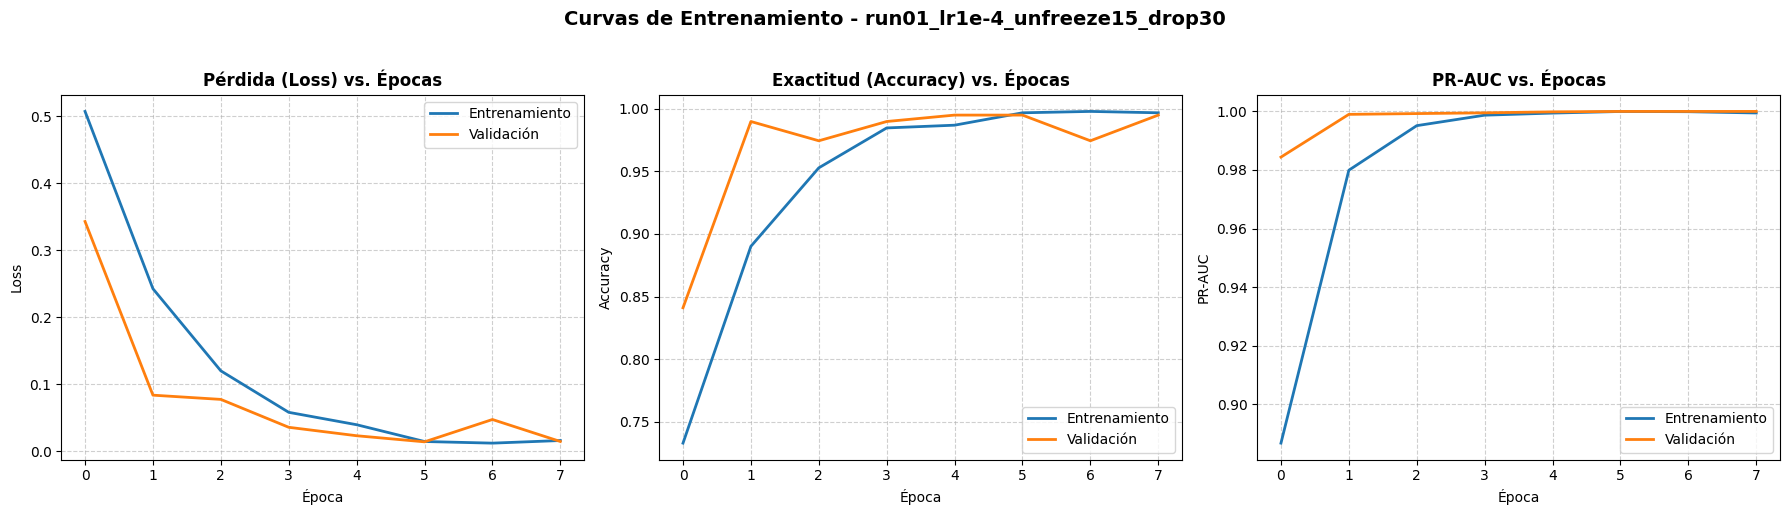

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Obtener la ruta de la corrida seleccionada en HPO
best_run_name = best['run_name']
history_path = Path(best['checkpoint']).parent / 'history.csv'

print(f"Cargando historial de entrenamiento de la mejor corrida: {best_run_name}")
print(f"Ruta del archivo: {history_path}")

if history_path.exists():
    hist_df = pd.read_csv(history_path)

    # Crear la figura para las gráficas
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Gráfica de Pérdida (Loss)
    axes[0].plot(hist_df['loss'], label='Entrenamiento', color='#1f77b4', linewidth=2)
    axes[0].plot(hist_df['val_loss'], label='Validación', color='#ff7f0e', linewidth=2)
    axes[0].set_title('Pérdida (Loss) vs. Épocas', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Época', fontsize=10)
    axes[0].set_ylabel('Loss', fontsize=10)
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Gráfica de Exactitud (Accuracy)
    axes[1].plot(hist_df['accuracy'], label='Entrenamiento', color='#1f77b4', linewidth=2)
    axes[1].plot(hist_df['val_accuracy'], label='Validación', color='#ff7f0e', linewidth=2)
    axes[1].set_title('Exactitud (Accuracy) vs. Épocas', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Época', fontsize=10)
    axes[1].set_ylabel('Accuracy', fontsize=10)
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    # Gráfica de PR-AUC (Precision-Recall AUC)
    axes[2].plot(hist_df['auc_pr'], label='Entrenamiento', color='#1f77b4', linewidth=2)
    axes[2].plot(hist_df['val_auc_pr'], label='Validación', color='#ff7f0e', linewidth=2)
    axes[2].set_title('PR-AUC vs. Épocas', fontsize=12, fontweight='bold')
    axes[2].set_xlabel('Época', fontsize=10)
    axes[2].set_ylabel('PR-AUC', fontsize=10)
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.6)

    plt.suptitle(f"Curvas de Entrenamiento - {best_run_name}", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Guardar las gráficas en la carpeta de la corrida seleccionada
    output_plot_path = Path(best['checkpoint']).parent / 'training_curves.png'
    plt.savefig(output_plot_path, dpi=150, bbox_inches='tight')
    print(f"Gráfica guardada en: {output_plot_path}")
    plt.show()
else:
    print(f"No se encontró el archivo de historial en la ruta: {history_path}")

In [56]:
!git status

On branch RIKDP-29-HU18-Evaluar-el-modelo-contra-la-métrica-objetivo
Your branch is up to date with 'origin/RIKDP-29-HU18-Evaluar-el-modelo-contra-la-métrica-objetivo'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	modified:   RIKUY_DEEP_G2.ipynb
	new file:   models/hu17_transfer_learning/mobilenetv2_hpo_20261031T202900Z.dvc

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   RIKUY_DEEP_G2.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	models/hu17_transfer_learning/.gitignore

